In [1]:
import os, sys, json, time, gc, hashlib, platform, zipfile, shutil, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import scipy
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.special import expit, logit
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
import sklearn
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
import joblib
import matplotlib.pyplot as plt
from IPython.display import display


@dataclass(frozen=True)
class Config:
    pipeline_version: str = 'btc_chrono_1.0'
    seed: int = 2026
    final_seeds: tuple = (2026, 3407)
    threads: int = min(6, os.cpu_count() or 2)
    half_life: float = 15.0
    minimum_recency_weight: float = 0.20
    unknown_weight: float = 0.15
    max_unknown_to_known_negative_weight: float = 0.60
    max_positive_weight: float = 4.0
    inner_stop_steps: int = 3
    early_stopping_rounds: int = 120
    lgb_rounds: int = 2200
    xgb_rounds: int = 1800
    cat_rounds: int = 2200
    use_cache: bool = True

CFG = Config()
INPUT_DIR = Path(os.environ.get('BTC_DATA_DIR', '.')).resolve()
OUT = Path(os.environ.get('BTC_OUTPUT_DIR', 'bitcoin_run')).resolve()
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'cache').mkdir(exist_ok=True)
(OUT / 'models').mkdir(exist_ok=True)
np.random.seed(CFG.seed)
VERSIONS = {m.__name__: m.__version__ for m in (np, pd, scipy, sklearn, lgb, xgb, cb)}
print('Python:', platform.python_version())
print('Packages:', json.dumps(VERSIONS, indent=2))
print('Configuration:', json.dumps(asdict(CFG), indent=2))

Python: 3.13.9
Packages: {
  "numpy": "2.3.5",
  "pandas": "2.3.3",
  "scipy": "1.16.3",
  "sklearn": "1.7.2",
  "lightgbm": "4.6.0",
  "xgboost": "3.1.2",
  "catboost": "1.2.10"
}
Configuration: {
  "pipeline_version": "btc_chrono_1.0",
  "seed": 2026,
  "final_seeds": [
    2026,
    3407
  ],
  "threads": 6,
  "half_life": 15.0,
  "minimum_recency_weight": 0.2,
  "unknown_weight": 0.15,
  "max_unknown_to_known_negative_weight": 0.6,
  "max_positive_weight": 4.0,
  "inner_stop_steps": 3,
  "early_stopping_rounds": 120,
  "lgb_rounds": 2200,
  "xgb_rounds": 1800,
  "cat_rounds": 2200,
  "use_cache": true
}


## Read and validate the actual schema

The supplied test has `index`, `txId`, `time_step`, and `feat_1`–`feat_165`.
The submission has **`index,target`**, not `txId,label`. IDs and time are excluded
from predictive features. Time controls validation and training weights.
Unknown labels are kept missing. Unexpected target encodings stop the run.

In [2]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(2**20), b''):
            h.update(block)
    return h.hexdigest()

def locate_input(stem):
    import re
    roots = [INPUT_DIR, INPUT_DIR / 'upload']
    if Path('/kaggle/input').exists():
        roots.append(Path('/kaggle/input'))
    pattern = re.compile(r'^' + re.escape(stem) + r'(?:\(\d+\))?\.csv$', re.I)
    candidates = set()
    for root in roots:
        if root.exists():
            iterator = root.rglob('*.csv') if str(root) == '/kaggle/input' else root.glob('*.csv')
            candidates.update(p.resolve() for p in iterator if pattern.match(p.name))
    if len(candidates) == 1:
        return next(iter(candidates))
    if len(candidates) > 1:
        hashes = {sha256_file(p) for p in candidates}
        if len(hashes) == 1:
            return sorted(candidates)[0]
        raise ValueError(f'Multiple different {stem} CSVs found. Set INPUT_DIR to one dataset: {sorted(candidates)}')
    if stem == 'train':
        zips = set()
        for root in roots:
            if root.exists():
                iterator = root.rglob('train*.zip') if str(root) == '/kaggle/input' else root.glob('train*.zip')
                zips.update(p.resolve() for p in iterator)
        if len(zips) == 1:
            with zipfile.ZipFile(next(iter(zips))) as z:
                members = [m for m in z.infolist() if pattern.match(Path(m.filename).name)
                           and '__MACOSX' not in m.filename and not m.is_dir()]
                if len(members) != 1:
                    raise ValueError('Expected exactly one training CSV in the ZIP.')
                dest = OUT / 'extracted_train.csv'
                with z.open(members[0]) as src, dest.open('wb') as dst:
                    shutil.copyfileobj(src, dst)
                return dest
    raise FileNotFoundError(f'Missing {stem}.csv. Set BTC_DATA_DIR or INPUT_DIR to your data directory.')

FILES = {
    "train": Path("data/train.csv"),
    "test": Path("data/test.csv"),
    "txs_edgelist": Path("data/txs_edgelist.csv"),
    "sample_submission": Path("data/sample_submission.csv"),
}

INPUT_HASHES = {k: sha256_file(p) for k, p in FILES.items()}

train = pd.read_csv(FILES["train"])
test = pd.read_csv(FILES["test"])
edges = pd.read_csv(FILES["txs_edgelist"])
sample = pd.read_csv(FILES["sample_submission"])


assert {'txId', 'time_step', 'label'} <= set(train.columns)
assert {'txId', 'time_step', 'index'} <= set(test.columns)
assert list(sample.columns) == ['index', 'target']
assert list(edges.columns) == ['txId1', 'txId2']
assert train.txId.is_unique and test.txId.is_unique and test['index'].is_unique
assert sample['index'].is_unique and set(sample['index']) == set(test['index'])
assert set(train.txId).isdisjoint(set(test.txId))
assert train.time_step.max() < test.time_step.min()
assert not train[['txId', 'time_step']].isna().any().any()
assert not test[['txId', 'time_step', 'index']].isna().any().any()

def parse_target(s):
    normalized = s.astype('string').str.strip().str.lower()
    missing_tokens = {'none', 'unknown', 'nan', 'na', 'null', ''}
    unknown = s.isna() | normalized.isin(missing_tokens)
    values = pd.to_numeric(s.where(~unknown), errors='coerce')
    bad = (~unknown) & (values.isna() | ~values.isin([0, 1]))
    if bad.any():
        raise ValueError(f'Unrecognized labels: {s[bad].unique().tolist()}')
    return values.astype(float).to_numpy()

y = parse_target(train.label)
FEATURES = sorted([c for c in train if c.startswith(('feat_', 'feature_'))],
                  key=lambda c: int(c.rsplit('_', 1)[1]))
assert len(FEATURES) == 165 and set(FEATURES) <= set(test)
assert set(train.time_step.unique()) == set(range(1, 36)), 'Review the fixed chronology for a different dataset.'
assert set(test.time_step.unique()) == set(range(36, 50))
N_TRAIN = len(train)
nodes = pd.concat([train[['txId', 'time_step'] + FEATURES],
                   test[['txId', 'time_step'] + FEATURES]], ignore_index=True)
time_all = nodes.time_step.to_numpy(dtype=np.int32)
known = np.isfinite(y)
print('Actual shapes:', {k: v.shape for k, v in [('train', train), ('test', test), ('edges', edges), ('sample', sample)]})
print('Label counts:', {'licit': int((y == 0).sum()), 'illicit': int((y == 1).sum()), 'unknown': int((~known).sum())})
print('Train periods:', sorted(train.time_step.unique()), '| test periods:', sorted(test.time_step.unique()))
print('Feature missing cells:', int(nodes[FEATURES].isna().sum().sum()))

Actual shapes: {'train': (141772, 168), 'test': (15329, 168), 'edges': (234355, 2), 'sample': (15329, 2)}
Label counts: {'licit': 27591, 'illicit': 3644, 'unknown': 110537}
Train periods: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35)] | test periods: [np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49)]
Feature missing cells: 0


## Label-free transaction graph features

Keep edge-only nodes for structural features: many test-period transactions have
no feature row, and dropping them would distort graph degree. Before using the
full edge list, verify that each weak component's observed nodes belong to one
time step. Disconnected future snapshots cannot affect a node's local features.
Fail closed if this assumption changes. The directed graph is also checked for
cycles; integer `txId` is never treated as a timestamp.

Features include degrees, predecessor/successor degree moments, two-hop walk
counts and forward/reverse PageRank normalized within each component. Component
ID and component size are deliberately omitted as predictors because they would
identify time snapshots. A component's size is used only for PageRank arithmetic.
The provided anonymized features already contain neighborhood aggregates.
No labels, predicted labels, future-time normalization, or external data enter
feature construction. Full within-snapshot topology assumes the competition's
supplied graph is available at inference; this is not instant transaction-time
detection before outgoing edges exist.

In [3]:
def build_features(nodes, edges, feature_cols):
    e = edges[['txId1', 'txId2']].drop_duplicates()
    assert not e.isna().any().any() and not e.txId1.eq(e.txId2).any()
    ids = pd.Index(np.unique(np.concatenate([nodes.txId.to_numpy(), e.txId1.to_numpy(), e.txId2.to_numpy()])))
    src, dst = ids.get_indexer(e.txId1), ids.get_indexer(e.txId2)
    take = ids.get_indexer(nodes.txId)
    n = len(ids)
    A = csr_matrix((np.ones(len(e), dtype=np.float32), (src, dst)), shape=(n, n))
    AT = A.T.tocsr()
    n_components, comp = connected_components(A, directed=True, connection='weak')
    component_times = pd.DataFrame({'component': comp[take], 'time': nodes.time_step}).groupby('component').time.agg(['min', 'max'])
    assert (component_times['min'] == component_times['max']).all(), 'Graph crosses time snapshots: revise graph features before training.'
    indeg = np.asarray(A.sum(axis=0)).ravel()
    outdeg = np.asarray(A.sum(axis=1)).ravel()
    # Kahn traversal verifies the causal DAG; no graph depth proxy for time is added.
    remaining = indeg.astype(np.int32).copy()
    queue = np.empty(n, dtype=np.int32)
    roots = np.flatnonzero(remaining == 0)
    queue[:len(roots)] = roots
    head, tail = 0, len(roots)
    while head < tail:
        u = queue[head]
        head += 1
        for v in A.indices[A.indptr[u]:A.indptr[u + 1]]:
            remaining[v] -= 1
            if remaining[v] == 0:
                queue[tail] = v
                tail += 1
    assert tail == n, 'A directed cycle was found in the supplied edge list.'
    csize = np.bincount(comp).astype(np.float64)
    values = {}
    def add(name, vector):
        values[name] = np.asarray(vector, dtype=np.float32)[take]
    add('g_log_in_degree', np.log1p(indeg))
    add('g_log_out_degree', np.log1p(outdeg))
    add('g_degree_balance', (indeg - outdeg) / (1 + indeg + outdeg))
    add('g_root', indeg == 0)
    add('g_leaf', outdeg == 0)
    add('g_isolated', (indeg + outdeg) == 0)
    for name, adjacency, degree in [('predecessor', AT, indeg), ('successor', A, outdeg)]:
        denom = np.maximum(degree, 1)
        for kind, vector in [('in', np.log1p(indeg)), ('out', np.log1p(outdeg))]:
            mean = adjacency @ vector / denom
            var = np.maximum(adjacency @ (vector * vector) / denom - mean * mean, 0)
            add(f'g_{name}_{kind}_degree_mean', mean)
            add(f'g_{name}_{kind}_degree_std', np.sqrt(var))
        walk_degree = indeg if name == 'predecessor' else outdeg
        add(f'g_{name}_log_two_hop_walks', np.log1p(adjacency @ walk_degree))
    # Expected baseline rank is one within every component, independent of other snapshots.
    for name, adjacency, degree in [('forward', A, outdeg), ('reverse', AT, indeg)]:
        rank = np.ones(n, dtype=np.float64)
        for _ in range(80):
            dangling = np.bincount(comp, weights=rank * (degree == 0), minlength=n_components) / csize
            updated = 0.15 + 0.85 * (adjacency.T @ (rank / np.maximum(degree, 1)) + dangling[comp])
            change = np.max(np.abs(updated - rank))
            rank = updated
            if change < 1e-7:
                break
        add(f'g_{name}_pagerank_log', np.log1p(rank))
    raw = nodes[feature_cols].apply(pd.to_numeric, errors='raise').to_numpy(dtype=np.float32, copy=True)
    raw[~np.isfinite(raw)] = np.nan
    finite = np.isfinite(raw)
    count = finite.sum(axis=1)
    clean = np.where(finite, raw, 0)
    mean = clean.sum(axis=1) / np.maximum(count, 1)
    var = np.maximum((clean * clean).sum(axis=1) / np.maximum(count, 1) - mean * mean, 0)
    values['row_missing_fraction'] = 1 - count / raw.shape[1]
    values['row_mean'] = mean.astype(np.float32)
    values['row_std'] = np.sqrt(var).astype(np.float32)
    values['row_abs_mean'] = (np.abs(clean).sum(axis=1) / np.maximum(count, 1)).astype(np.float32)
    values['row_large_fraction'] = ((np.abs(clean) > 3).sum(axis=1) / np.maximum(count, 1)).astype(np.float32)
    frame = pd.concat([pd.DataFrame(raw, columns=feature_cols), pd.DataFrame(values)], axis=1).astype(np.float32)
    info = {'graph_nodes': n, 'edges': len(e), 'components': n_components,
            'components_crossing_time': 0, 'dag_nodes_visited': tail,
            'feature_count': frame.shape[1], 'edge_only_nodes': n - len(nodes)}
    return frame, info

X, GRAPH_INFO = build_features(nodes, edges, FEATURES)
assert not {'txId', 'index', 'time_step', 'label', 'target'} & set(X.columns)
assert not np.isinf(X.to_numpy()).any()
print('Graph and features:', GRAPH_INFO)
print('Feature matrix:', X.shape, '| memory MiB:', round(X.memory_usage(deep=True).sum() / 2**20, 1))
RUN_ID = hashlib.sha256(json.dumps({'config': asdict(CFG), 'inputs': INPUT_HASHES,
                                  'versions': VERSIONS, 'features': list(X)}, sort_keys=True).encode()).hexdigest()[:16]
print('Run fingerprint:', RUN_ID)

Graph and features: {'graph_nodes': 203769, 'edges': 234355, 'components': 49, 'components_crossing_time': 0, 'dag_nodes_visited': 203769, 'feature_count': 188, 'edge_only_nodes': 46668}
Feature matrix: (157101, 188) | memory MiB: 112.7
Run fingerprint: a3dc9ceac6b5e0ba


## Chronological training and class imbalance

| Role | Fit through | Predict | Purpose |
|---|---:|---|---|
| tune_1 | 10 | 11–14 | First out-of-time tuning block |
| tune_2 | 14 | 15–18 | Second out-of-time tuning block |
| guard | 18 | 19–21 | Gate background blending and residual correction |
| audit | 21 | 22–35 | Untouched 14-period assessment of the frozen recipe |
| final | 35 | 36–49 | Fit all training data, score the test |

For every fit, use the last three **training** periods for internal early
stopping. Then refit that learner on all periods through the fit cutoff using
the chosen number of trees. Outer validation labels never control tree count.

Recency weight is `max(0.20, 2**(-age/15))`. Positive class weighting is the
square root of the weighted negative/positive ratio, capped at 4; it is applied
exactly once. For the background branch, unknowns get weight at most 0.15, with
total unknown weight capped at 60% of known-negative weight. Unknowns are noisy
background examples, **not confirmed negatives** or a formally unbiased PU
estimator. Both validation and early stopping score confirmed labels only.
A prior-odds adjustment removes the explicit positive weight from model scores;
later OOF calibration still cannot ensure calibration under future distribution
shift. ROC-AUC is the selection metric; average precision is a guard metric.

In [4]:
ALGORITHMS = ('lightgbm', 'xgboost', 'catboost')
BRANCHES = ('supervised', 'background')
PRED_COLUMNS = [f'{b}_{a}' for b in BRANCHES for a in ALGORITHMS]
SPLITS = [('tune_1', 10, 11, 14), ('tune_2', 14, 15, 18),
          ('guard', 18, 19, 21), ('audit', 21, 22, 35)]

def safe_logit(p):
    return logit(np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6))

def training_data(cutoff, branch):
    eligible = time_all[:N_TRAIN] <= cutoff
    idx = np.flatnonzero(eligible & (known if branch == 'supervised' else True))
    target = np.nan_to_num(y[idx], nan=0).astype(np.int8)
    weights = np.maximum(CFG.minimum_recency_weight,
                         2.0 ** (-(cutoff - time_all[idx]) / CFG.half_life))
    unknown_rows = ~known[idx]
    if branch == 'background':
        known_neg_mass = weights[known[idx] & (target == 0)].sum()
        unknown_mass = weights[unknown_rows].sum()
        uweight = min(CFG.unknown_weight,
                      CFG.max_unknown_to_known_negative_weight * known_neg_mass / max(unknown_mass, 1e-12))
        weights[unknown_rows] *= uweight
    positive_multiplier = float(np.clip(np.sqrt(weights[target == 0].sum() /
                                                max(weights[target == 1].sum(), 1e-12)), 1, CFG.max_positive_weight))
    weights[target == 1] *= positive_multiplier
    weights /= weights.mean()
    assert set(np.unique(target)) == {0, 1}
    assert np.all(time_all[idx] <= cutoff)
    return idx, target, weights.astype(np.float32), positive_multiplier

def fit_one(algorithm, idx, target, weights, seed, rounds, eval_idx=None):
    valid = eval_idx is not None
    xtrain = X.iloc[idx]
    if algorithm == 'lightgbm':
        model = lgb.LGBMClassifier(
            n_estimators=rounds, learning_rate=0.035, num_leaves=31,
            min_child_samples=55, colsample_bytree=0.85, subsample=0.85,
            subsample_freq=1, reg_alpha=0.15, reg_lambda=12,
            objective='binary', metric='auc', random_state=seed,
            n_jobs=CFG.threads, deterministic=True, force_col_wise=True, verbosity=-1)
        extra = dict(eval_set=[(X.iloc[eval_idx], y[eval_idx])], eval_metric='auc',
                     callbacks=[lgb.early_stopping(CFG.early_stopping_rounds, first_metric_only=True, verbose=False)]) if valid else {}
        model.fit(xtrain, target, sample_weight=weights, **extra)
        best = int(model.best_iteration_ or rounds) if valid else rounds
    elif algorithm == 'xgboost':
        model = xgb.XGBClassifier(
            n_estimators=rounds, learning_rate=0.04, max_depth=5,
            min_child_weight=5, subsample=0.85, colsample_bytree=0.85,
            reg_alpha=0.05, reg_lambda=20, tree_method='hist', max_bin=256,
            objective='binary:logistic', eval_metric='auc', random_state=seed,
            n_jobs=CFG.threads, early_stopping_rounds=CFG.early_stopping_rounds if valid else None)
        extra = dict(eval_set=[(X.iloc[eval_idx], y[eval_idx])]) if valid else {}
        model.fit(xtrain, target, sample_weight=weights, verbose=False, **extra)
        best = int(model.best_iteration + 1) if valid else rounds
    else:
        model = cb.CatBoostClassifier(
            iterations=rounds, learning_rate=0.04, depth=6, l2_leaf_reg=12,
            loss_function='Logloss', eval_metric='AUC', bootstrap_type='Bernoulli',
            subsample=0.85, rsm=0.85, random_strength=0.7,
            leaf_estimation_iterations=5, random_seed=seed,
            thread_count=CFG.threads, allow_writing_files=False, verbose=False)
        extra = dict(eval_set=(X.iloc[eval_idx], y[eval_idx]), use_best_model=True,
                     early_stopping_rounds=CFG.early_stopping_rounds) if valid else {}
        model.fit(xtrain, target, sample_weight=weights, **extra)
        best = int(model.get_best_iteration() + 1) if valid else rounds
    return model, max(1, best)

ROUND_CAP = dict(zip(ALGORITHMS, [CFG.lgb_rounds, CFG.xgb_rounds, CFG.cat_rounds]))

def run_stage(name, cutoff, predict_idx, final=False):
    seeds = CFG.final_seeds if final else (CFG.seed,)
    cache = OUT / 'cache' / f'{RUN_ID}_{name}.npz'
    meta_path = cache.with_suffix('.json')
    if CFG.use_cache and cache.exists() and meta_path.exists():
        saved = np.load(cache)
        metadata = json.loads(meta_path.read_text())
        if np.array_equal(saved['indices'], predict_idx):
            print(f'{name}: reusing matching prediction cache', flush=True)
            return saved['predictions'], metadata
    inner_cut = cutoff - CFG.inner_stop_steps
    eval_idx = np.flatnonzero(known & (time_all[:N_TRAIN] > inner_cut) & (time_all[:N_TRAIN] <= cutoff))
    assert set(y[eval_idx]) == {0, 1} and time_all[eval_idx].min() > inner_cut
    assert time_all[predict_idx].min() > cutoff
    result = np.empty((len(predict_idx), 6), dtype=np.float64)
    metadata = {'stage': name, 'cutoff': cutoff, 'inner_cutoff': inner_cut,
                'prediction_start': int(time_all[predict_idx].min()),
                'prediction_end': int(time_all[predict_idx].max()), 'models': []}
    column = 0
    for branch in BRANCHES:
        inner_i, inner_y, inner_w, _ = training_data(inner_cut, branch)
        full_i, full_y, full_w, positive_multiplier = training_data(cutoff, branch)
        for algorithm in ALGORITHMS:
            started = time.time()
            print(f'{name}: {branch}/{algorithm} | stop selection <= {cutoff}, outer labels excluded', flush=True)
            pilot, best_rounds = fit_one(algorithm, inner_i, inner_y, inner_w, CFG.seed,
                                        ROUND_CAP[algorithm], eval_idx=eval_idx)
            del pilot
            seed_predictions = []
            for seed in seeds:
                model, _ = fit_one(algorithm, full_i, full_y, full_w, seed, best_rounds)
                prob = model.predict_proba(X.iloc[predict_idx])[:, 1]
                seed_predictions.append(expit(safe_logit(prob) - np.log(positive_multiplier)))
                if final:
                    suffix = {'lightgbm': 'txt', 'xgboost': 'json', 'catboost': 'cbm'}[algorithm]
                    destination = OUT / 'models' / f'{branch}_{algorithm}_{seed}.{suffix}'
                    if algorithm == 'lightgbm':
                        model.booster_.save_model(str(destination))
                    else:
                        model.save_model(str(destination))
                if name == 'tune_1' and branch == 'supervised' and algorithm == 'lightgbm':
                    metadata['importance'] = dict(zip(X.columns, model.booster_.feature_importance(importance_type='gain').tolist()))
                del model
                gc.collect()
            result[:, column] = np.mean(seed_predictions, axis=0)
            record = {'branch': branch, 'algorithm': algorithm, 'rounds': best_rounds,
                      'positive_multiplier': positive_multiplier, 'training_rows': len(full_i),
                      'seconds': round(time.time() - started, 2), 'seeds': list(seeds)}
            metadata['models'].append(record)
            print('  completed:', record, flush=True)
            column += 1
    assert np.isfinite(result).all() and ((result >= 0) & (result <= 1)).all()
    np.savez_compressed(cache, indices=predict_idx, predictions=result)
    meta_path.write_text(json.dumps(metadata, indent=2))
    return result, metadata

def metrics(y_true, pred):
    return {'roc_auc': float(roc_auc_score(y_true, pred)),
            'average_precision': float(average_precision_score(y_true, pred))}

def period_metrics(frame, pred):
    rows = []
    for step in sorted(frame.time_step.unique()):
        m = frame.time_step.to_numpy() == step
        labels = frame.label.to_numpy()[m]
        rows.append({'time_step': int(step), 'n': int(m.sum()), 'illicit': int(labels.sum()),
                     **(metrics(labels, np.asarray(pred)[m]) if len(np.unique(labels)) == 2
                        else {'roc_auc': np.nan, 'average_precision': np.nan})})
    return pd.DataFrame(rows)

def stage_frame(name, cutoff, start, end):
    idx = np.flatnonzero(known & (time_all[:N_TRAIN] >= start) & (time_all[:N_TRAIN] <= end))
    pred, metadata = run_stage(name, cutoff, idx)
    frame = pd.DataFrame(pred, columns=PRED_COLUMNS)
    frame['row_id'] = idx
    frame['label'] = y[idx].astype(np.int8)
    frame['time_step'] = time_all[idx]
    frame['fold'] = name
    print(name, 'base ROC-AUC:', {c: round(roc_auc_score(frame.label, frame[c]), 5) for c in PRED_COLUMNS})
    return frame, metadata

## Generate chronological tuning predictions

Model parameters are fixed in advance; only a small, regularized set of voting
weights and blend strengths is considered. This avoids a large search over a
few historical periods. These tuning scores are **not** an unbiased estimate of
the selected ensemble. The later audit is the reported generalization check.

In [5]:
tuning_frames, STAGE_METADATA = [], {}
for split in SPLITS[:2]:
    frame, metadata = stage_frame(*split)
    tuning_frames.append(frame)
    STAGE_METADATA[split[0]] = metadata
tuning = pd.concat(tuning_frames, ignore_index=True)
display(pd.DataFrame([{c: roc_auc_score(f.label, f[c]) for c in PRED_COLUMNS}
                     for f in tuning_frames], index=['tune_1', 'tune_2']).round(5))

tune_1: reusing matching prediction cache
tune_1 base ROC-AUC: {'supervised_lightgbm': 0.99726, 'supervised_xgboost': 0.99708, 'supervised_catboost': 0.99689, 'background_lightgbm': 0.99729, 'background_xgboost': 0.99763, 'background_catboost': 0.99737}
tune_2: reusing matching prediction cache
tune_2 base ROC-AUC: {'supervised_lightgbm': 0.9967, 'supervised_xgboost': 0.99678, 'supervised_catboost': 0.99687, 'background_lightgbm': 0.99639, 'background_xgboost': 0.9942, 'background_catboost': 0.99626}


,supervised_lightgbm,supervised_xgboost,supervised_catboost,background_lightgbm,background_xgboost,background_catboost
tune_1,0.99726,0.99708,0.99689,0.99729,0.99763,0.99737
tune_2,0.99670,0.99678,0.99687,0.99639,0.99420,0.99626


In [6]:
WEIGHT_GRID = np.array([[1/3, 1/3, 1/3], [.5, .25, .25], [.25, .5, .25], [.25, .25, .5],
                        [.6, .2, .2], [.2, .6, .2], [.2, .2, .6],
                        [.45, .45, .10], [.45, .10, .45], [.10, .45, .45]])

def stability_score(frame, pred):
    # Equal importance for the two chronological blocks, with a small worst-block penalty.
    scores = np.array([roc_auc_score(frame.loc[frame.fold == f, 'label'],
                                    np.asarray(pred)[frame.fold.to_numpy() == f])
                       for f in frame.fold.unique()])
    return float(0.8 * scores.mean() + 0.2 * scores.min())

def pick_weights(branch):
    matrix = tuning[[f'{branch}_{a}' for a in ALGORITHMS]].to_numpy()
    scores = [stability_score(tuning, matrix @ w) - 0.0005 * np.sum((w - 1/3)**2) for w in WEIGHT_GRID]
    return WEIGHT_GRID[int(np.argmax(scores))].copy()

VOTE_WEIGHTS = {b: pick_weights(b) for b in BRANCHES}
CALIBRATORS = {}
for branch in BRANCHES:
    p = tuning[[f'{branch}_{a}' for a in ALGORITHMS]].to_numpy() @ VOTE_WEIGHTS[branch]
    calibration = LogisticRegression(C=0.5, solver='lbfgs', max_iter=500)
    calibration.fit(safe_logit(p).reshape(-1, 1), tuning.label)
    assert calibration.coef_[0, 0] > 0, 'Calibration must preserve within-branch ranking.'
    CALIBRATORS[branch] = {'slope': float(calibration.coef_[0, 0]),
                           'intercept': float(calibration.intercept_[0])}

def branch_scores(frame):
    answer = {}
    for branch in BRANCHES:
        p = frame[[f'{branch}_{a}' for a in ALGORITHMS]].to_numpy() @ VOTE_WEIGHTS[branch]
        c = CALIBRATORS[branch]
        answer[branch] = expit(c['slope'] * safe_logit(p) + c['intercept'])
    return answer['supervised'], answer['background']

def adaptive_blend(frame, base_alpha, disagreement_penalty):
    ps, pb = branch_scores(frame)
    zs, zb = safe_logit(ps), safe_logit(pb)
    alpha = base_alpha / (1 + disagreement_penalty * np.abs(zs - zb))
    return expit((1 - alpha) * zs + alpha * zb), alpha

blend_candidates = []
for a in [0.0, 0.1, 0.2, 0.35, 0.5]:
    for gamma in ([0.0] if a == 0 else [0.0, 0.5, 1.0]):
        p, _ = adaptive_blend(tuning, a, gamma)
        score = stability_score(tuning, p) - 0.0003 * a
        blend_candidates.append({'alpha': a, 'gamma': gamma, 'score': score})
BLEND = max(blend_candidates, key=lambda x: x['score']).copy()
print('Soft-vote weights:', {k: dict(zip(ALGORITHMS, v.tolist())) for k, v in VOTE_WEIGHTS.items()})
print('OOF branch calibration:', CALIBRATORS)
print('Selected adaptive blend:', BLEND)
display(pd.DataFrame(blend_candidates).sort_values('score', ascending=False).head(8))

Soft-vote weights: {'supervised': {'lightgbm': 0.3333333333333333, 'xgboost': 0.3333333333333333, 'catboost': 0.3333333333333333}, 'background': {'lightgbm': 0.5, 'xgboost': 0.25, 'catboost': 0.25}}
OOF branch calibration: {'supervised': {'slope': 1.6170145537540452, 'intercept': 2.0349373598126443}, 'background': {'slope': 1.9750443806811235, 'intercept': 7.2828358308783825}}
Selected adaptive blend: {'alpha': 0.5, 'gamma': 0.0, 'score': 0.9973258885646104}


,alpha,gamma,score
10,0.50,0.0,0.997326
7,0.35,0.0,0.997303
4,0.20,0.0,0.997277
1,0.10,0.0,0.997191
8,0.35,0.5,0.997153
11,0.50,0.5,0.997151
5,0.20,0.5,0.997125
2,0.10,0.5,0.997113


## Later-period guard and bounded residual correction

The blend is retained only if its 19–21 ROC-AUC is no more than 0.001 below
the supervised vote, its mean per-period AUC is no more than 0.002 below,
and its average precision is no more than 0.005 below.

The residual model learns `y - p` on tuning OOF predictions only, with shallow
trees and strong regularization. Its features include branch disagreement,
six base logits and twelve feature columns ranked by the first training fold's
LightGBM. Residual updates are clipped to at most 0.2 log-odds (at most about
five probability points). Enable a correction only if it improves guard
ROC-AUC by at least 0.0005, improves mean per-period AUC, loses no more than
0.003 AUC in any guard period, and loses no more than 0.002 average precision.
Zero correction and zero background weight are valid outcomes of these guards.
After the guard, freeze all selection choices before opening the audit.

In [7]:
guard, guard_meta = stage_frame(*SPLITS[2])
STAGE_METADATA['guard'] = guard_meta
guard_base, _ = adaptive_blend(guard, BLEND['alpha'], BLEND['gamma'])
guard_sup, _ = branch_scores(guard)
delta = period_metrics(guard, guard_base).roc_auc.to_numpy() - period_metrics(guard, guard_sup).roc_auc.to_numpy()
blend_gain = roc_auc_score(guard.label, guard_base) - roc_auc_score(guard.label, guard_sup)
blend_ap_gain = average_precision_score(guard.label, guard_base) - average_precision_score(guard.label, guard_sup)
BLEND_GUARD = {'pooled_auc_gain': float(blend_gain), 'mean_period_auc_gain': float(np.nanmean(delta)),
               'average_precision_gain': float(blend_ap_gain)}
if blend_gain < -0.001 or np.nanmean(delta) < -0.002 or blend_ap_gain < -0.005:
    BLEND['alpha'] = 0.0
    BLEND['gamma'] = 0.0
    BLEND_GUARD['background_enabled'] = False
else:
    BLEND_GUARD['background_enabled'] = bool(BLEND['alpha'] > 0)
guard_base, _ = adaptive_blend(guard, BLEND['alpha'], BLEND['gamma'])
tuning_base, _ = adaptive_blend(tuning, BLEND['alpha'], BLEND['gamma'])

importance = STAGE_METADATA['tune_1']['importance']
RESIDUAL_RAW_FEATURES = sorted(importance, key=importance.get, reverse=True)[:12]

def residual_features(frame, base):
    ps, pb = branch_scores(frame)
    extras = pd.DataFrame({
        'base_logit': safe_logit(base), 'supervised_logit': safe_logit(ps),
        'background_logit': safe_logit(pb), 'branch_gap': pb - ps,
        'model_dispersion': np.std(safe_logit(frame[PRED_COLUMNS].to_numpy()), axis=1)})
    for c in PRED_COLUMNS:
        extras[f'z_{c}'] = safe_logit(frame[c])
    own = X.iloc[frame.row_id.to_numpy()][RESIDUAL_RAW_FEATURES].reset_index(drop=True)
    return pd.concat([extras, own], axis=1).astype(np.float32)

def fit_residual(frame, base):
    model = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.03, num_leaves=4,
                             max_depth=2, min_child_samples=150, reg_lambda=50,
                             reg_alpha=1, colsample_bytree=0.8, objective='regression',
                             n_jobs=CFG.threads, random_state=CFG.seed, verbosity=-1,
                             deterministic=True, force_col_wise=True)
    weight = np.maximum(0.3, 2 ** (-(frame.time_step.max() - frame.time_step.to_numpy()) / CFG.half_life))
    model.fit(residual_features(frame, base), frame.label.to_numpy() - base, sample_weight=weight)
    return model

def apply_residual(model, frame, base, eta):
    if eta == 0:
        return np.asarray(base).copy()
    r = model.predict(residual_features(frame, base))
    direction = np.clip(r / (base * (1 - base) + 0.05), -1, 1)
    return expit(safe_logit(base) + eta * direction)

residual_pilot = fit_residual(tuning, tuning_base)
RESIDUAL_ETA = 0.0
residual_guard_rows = []
baseline_m = metrics(guard.label, guard_base)
best_guard_auc = baseline_m['roc_auc']
for eta in [0.05, 0.10, 0.20]:
    proposed = apply_residual(residual_pilot, guard, guard_base, eta)
    m = metrics(guard.label, proposed)
    d = period_metrics(guard, proposed).roc_auc.to_numpy() - period_metrics(guard, guard_base).roc_auc.to_numpy()
    allowed = bool(m['roc_auc'] >= baseline_m['roc_auc'] + 0.0005
                   and np.nanmean(d) > 0 and np.nanmin(d) >= -0.003
                   and m['average_precision'] >= baseline_m['average_precision'] - 0.002)
    residual_guard_rows.append({'eta': eta, **m, 'mean_period_auc_gain': float(np.nanmean(d)),
                                 'worst_period_auc_gain': float(np.nanmin(d)), 'passed': allowed})
    if allowed and m['roc_auc'] > best_guard_auc:
        RESIDUAL_ETA, best_guard_auc = eta, m['roc_auc']
development = pd.concat([tuning, guard], ignore_index=True)
development_base, _ = adaptive_blend(development, BLEND['alpha'], BLEND['gamma'])
RESIDUAL_MODEL = fit_residual(development, development_base) if RESIDUAL_ETA else None
FROZEN_RECIPE = {'vote_weights': {b: w.tolist() for b, w in VOTE_WEIGHTS.items()},
                 'calibration': CALIBRATORS, 'blend': BLEND, 'blend_guard': BLEND_GUARD,
                 'residual_eta': RESIDUAL_ETA, 'residual_features': RESIDUAL_RAW_FEATURES,
                 'residual_guard_results': residual_guard_rows,
                 'selection_labels_max_time': 21, 'audit_start': 22}
(OUT / 'frozen_recipe.json').write_text(json.dumps(FROZEN_RECIPE, indent=2))
FROZEN_RECIPE_HASH = sha256_file(OUT / 'frozen_recipe.json')
print('Background guard:', BLEND_GUARD)
print('Frozen background maximum weight:', BLEND['alpha'], '| residual log-odds limit:', RESIDUAL_ETA)
display(pd.DataFrame(residual_guard_rows))

guard: reusing matching prediction cache
guard base ROC-AUC: {'supervised_lightgbm': 0.98878, 'supervised_xgboost': 0.9886, 'supervised_catboost': 0.98551, 'background_lightgbm': 0.98697, 'background_xgboost': 0.98726, 'background_catboost': 0.9826}
Background guard: {'pooled_auc_gain': 8.002560819464488e-05, 'mean_period_auc_gain': -1.4836658197829125e-05, 'average_precision_gain': -0.0014669975991227213, 'background_enabled': True}
Frozen background maximum weight: 0.5 | residual log-odds limit: 0.0


,eta,roc_auc,average_precision,mean_period_auc_gain,worst_period_auc_gain,passed
0,0.05,0.987834,0.969252,-4.757936e-08,-0.000037,False
1,0.10,0.987848,0.969309,1.955626e-06,-0.000037,False
2,0.20,0.987869,0.969380,4.103164e-05,0.000030,False


## Locked 14-period audit

This is the first evaluation of the selected recipe on time steps 22–35.
Weights, calibration, blending and correction strength are already frozen.
Do not tune them after looking at this section. Report pooled ROC-AUC alongside
per-period AUC and average precision, because prevalence and performance vary
over time. The block bootstrap resamples whole time periods and gives a rough
uncertainty interval; it is not a guarantee about a future leaderboard.

audit: reusing matching prediction cache
audit base ROC-AUC: {'supervised_lightgbm': 0.85119, 'supervised_xgboost': 0.82998, 'supervised_catboost': 0.82802, 'background_lightgbm': 0.78218, 'background_xgboost': 0.77153, 'background_catboost': 0.77338}


,model,roc_auc,average_precision
0,supervised_lightgbm,0.851189,0.791686
1,supervised_xgboost,0.829977,0.785666
2,supervised_catboost,0.828016,0.780025
3,background_lightgbm,0.782181,0.772523
4,background_xgboost,0.771529,0.771284
5,background_catboost,0.773375,0.773438
6,supervised_soft_vote,0.830005,0.785053
7,background_soft_vote,0.767736,0.774479
8,adaptive_blend,0.791965,0.780792
9,frozen_final_recipe,0.791965,0.780792


,time_step,n,illicit,roc_auc,average_precision
0,22,1763,158,0.99894,0.99187
1,23,1187,53,0.92197,0.76735
2,24,1126,137,0.50057,0.45011
3,25,594,118,0.99959,0.99829
4,26,517,96,0.89633,0.87513
5,27,206,24,0.99863,0.99167
6,28,284,85,1.00000,1.00000
7,29,1174,329,0.53889,0.56820
8,30,524,83,0.99107,0.95279
9,31,710,106,0.58519,0.56358


Locked audit: {'roc_auc': 0.7919652281878875, 'average_precision': 0.7807918926337636} | time-block bootstrap 95% AUC interval: [0.6784254861161441, 0.945029549204083]


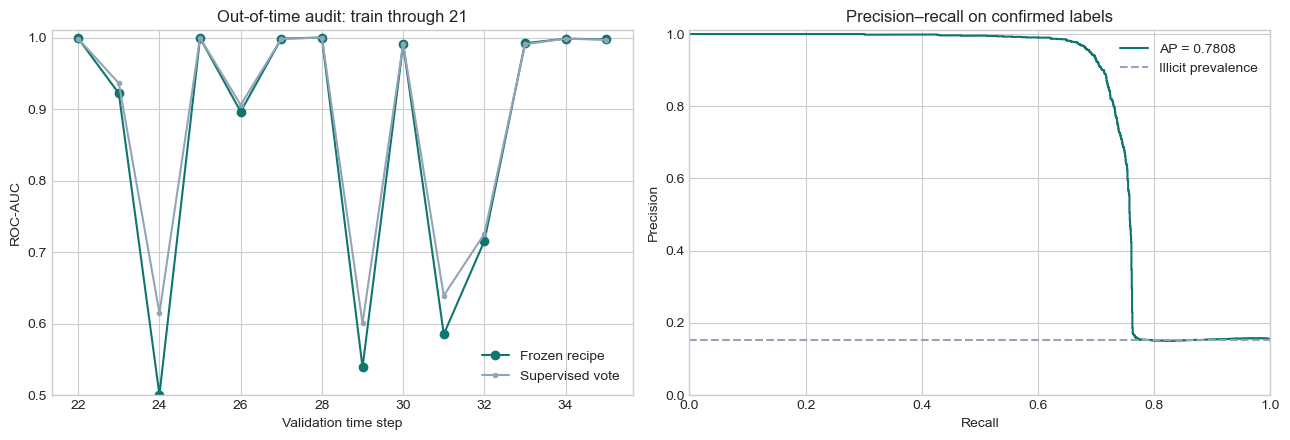

In [8]:
audit, audit_meta = stage_frame(*SPLITS[3])
STAGE_METADATA['audit'] = audit_meta
assert sha256_file(OUT / 'frozen_recipe.json') == FROZEN_RECIPE_HASH
audit_base, audit_alpha = adaptive_blend(audit, BLEND['alpha'], BLEND['gamma'])
audit_final = apply_residual(RESIDUAL_MODEL, audit, audit_base, RESIDUAL_ETA)
audit_sup, audit_background = branch_scores(audit)
AUDIT_METRICS = metrics(audit.label, audit_final)
audit_comparison = pd.DataFrame([
    {'model': c, **metrics(audit.label, audit[c])} for c in PRED_COLUMNS
] + [{'model': 'supervised_soft_vote', **metrics(audit.label, audit_sup)},
     {'model': 'background_soft_vote', **metrics(audit.label, audit_background)},
     {'model': 'adaptive_blend', **metrics(audit.label, audit_base)},
     {'model': 'frozen_final_recipe', **AUDIT_METRICS}])
audit_by_time = period_metrics(audit, audit_final)
display(audit_comparison.round(6))
display(audit_by_time.round(5))

def time_block_bootstrap(frame, pred, repeats=500):
    rng = np.random.default_rng(CFG.seed)
    blocks = [np.flatnonzero(frame.time_step.to_numpy() == s) for s in sorted(frame.time_step.unique())]
    aucs = []
    for _ in range(repeats):
        idx = np.concatenate([blocks[j] for j in rng.integers(len(blocks), size=len(blocks))])
        if len(np.unique(frame.label.to_numpy()[idx])) == 2:
            aucs.append(roc_auc_score(frame.label.to_numpy()[idx], np.asarray(pred)[idx]))
    return [float(v) for v in np.quantile(aucs, [0.025, 0.975])]

AUDIT_CI = time_block_bootstrap(audit, audit_final)
print('Locked audit:', AUDIT_METRICS, '| time-block bootstrap 95% AUC interval:', AUDIT_CI)
audit['prediction'] = audit_final
audit.to_csv(OUT / 'audit_predictions.csv', index=False)
audit_by_time.to_csv(OUT / 'audit_by_time.csv', index=False)
audit_comparison.to_csv(OUT / 'audit_comparison.csv', index=False)

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(audit_by_time.time_step, audit_by_time.roc_auc, marker='o', color='#0f766e', label='Frozen recipe')
sup_periods = period_metrics(audit, audit_sup)
axes[0].plot(sup_periods.time_step, sup_periods.roc_auc, marker='.', color='#94a3b8', label='Supervised vote')
axes[0].set(title='Out-of-time audit: train through 21', xlabel='Validation time step', ylabel='ROC-AUC', ylim=(0.5, 1.01))
axes[0].legend(frameon=False)
precision, recall, _ = precision_recall_curve(audit.label, audit_final)
axes[1].plot(recall, precision, color='#0f766e', label=f"AP = {AUDIT_METRICS['average_precision']:.4f}")
axes[1].axhline(audit.label.mean(), color='#94a3b8', linestyle='--', label='Illicit prevalence')
axes[1].set(title='Precision–recall on confirmed labels', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.01))
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / 'validation.png', dpi=160, bbox_inches='tight')
plt.show()

## Recent-period diagnostic with the same frozen recipe

The original 14-period audit showed substantial distribution drift. This
additional diagnostic trains through 30 and predicts 31–35 to measure the same
recipe with more recent training examples. It was added after inspecting the
longer audit. Its periods overlap that audit, so it is not a new untouched
holdout or a 14-period forecast. No weights, hyperparameters or feature choices
are retuned from this result. Both results must be considered together.

In [9]:
recent, recent_meta = stage_frame('recent_diagnostic', 30, 31, 35)
STAGE_METADATA['recent_diagnostic'] = recent_meta
recent_base, _ = adaptive_blend(recent, BLEND['alpha'], BLEND['gamma'])
recent_final = apply_residual(RESIDUAL_MODEL, recent, recent_base, RESIDUAL_ETA)
RECENT_METRICS = metrics(recent.label, recent_final)
recent_by_time = period_metrics(recent, recent_final)
print('Recent-period diagnostic:', RECENT_METRICS)
display(recent_by_time.round(5))
recent['prediction'] = recent_final
recent.to_csv(OUT / 'recent_predictions.csv', index=False)
recent_by_time.to_csv(OUT / 'recent_by_time.csv', index=False)
assert sha256_file(OUT / 'frozen_recipe.json') == FROZEN_RECIPE_HASH

recent_diagnostic: reusing matching prediction cache
recent_diagnostic base ROC-AUC: {'supervised_lightgbm': 0.99764, 'supervised_xgboost': 0.99474, 'supervised_catboost': 0.99837, 'background_lightgbm': 0.99879, 'background_xgboost': 0.9984, 'background_catboost': 0.99898}
Recent-period diagnostic: {'roc_auc': 0.998926182513139, 'average_precision': 0.995348453270947}


,time_step,n,illicit,roc_auc,average_precision
0,31,710,106,0.99703,0.98817
1,32,1323,342,0.99958,0.99856
2,33,441,23,0.99334,0.92095
3,34,515,37,0.99966,0.99589
4,35,1341,182,0.99855,0.99366


## Refit and create the single submission

Refit all six learners using training periods 1–35, with the same nested
training-only stopping rule. Average two fixed seeds within each learner for
the final fit; the audit used one fixed seed. Voting weights, calibration,
adaptive blend and correction strength remain frozen. If enabled, the residual
model is refit on all chronological OOF residuals, including the completed
audit. The audit therefore measures the pre-refit recipe, not this exact fitted
model or a guarantee of its score. Future test labels are never read or inferred
from external versions of this public dataset.

Predictions are probabilities/scores for **illicit** transactions, not hard
class labels. Do not reverse them or threshold them for ROC-AUC. The export is
joined by the sample's `index` and checked after being written to disk.

In [10]:
test_idx = np.arange(N_TRAIN, len(nodes))
test_predictions, final_meta = run_stage('final', 35, test_idx, final=True)
STAGE_METADATA['final'] = final_meta
test_frame = pd.DataFrame(test_predictions, columns=PRED_COLUMNS)
test_frame['row_id'] = test_idx
test_frame['time_step'] = time_all[test_idx]
all_oof = pd.concat([development, audit.drop(columns='prediction')], ignore_index=True)
if RESIDUAL_ETA:
    all_base, _ = adaptive_blend(all_oof, BLEND['alpha'], BLEND['gamma'])
    RESIDUAL_MODEL = fit_residual(all_oof, all_base)
    RESIDUAL_MODEL.booster_.save_model(str(OUT / 'models' / 'residual.txt'))
test_base, test_alpha = adaptive_blend(test_frame, BLEND['alpha'], BLEND['gamma'])
test_risk = apply_residual(RESIDUAL_MODEL, test_frame, test_base, RESIDUAL_ETA)
assert np.isfinite(test_risk).all() and ((test_risk > 0) & (test_risk < 1)).all()
prediction_by_index = pd.Series(test_risk, index=test['index'].to_numpy())
submission = sample.copy()
submission['target'] = submission['index'].map(prediction_by_index)
assert len(submission) == len(test) == len(sample)
assert submission['index'].equals(sample['index'])
assert list(submission.columns) == ['index', 'target']
assert submission.target.notna().all() and submission.target.between(0, 1).all()
assert submission.target.nunique() > 100
SUBMISSION_PATH = OUT / 'submission.csv'
submission.to_csv(SUBMISSION_PATH, index=False, float_format='%.12g')
roundtrip = pd.read_csv(SUBMISSION_PATH)
pd.testing.assert_series_equal(roundtrip['index'], sample['index'])
assert roundtrip.shape == sample.shape and list(roundtrip) == list(sample)
assert np.isfinite(roundtrip.target).all() and roundtrip.target.between(0, 1).all()
assert np.allclose(roundtrip.target, submission.target, atol=1e-11, rtol=1e-10)
assert sha256_file(OUT / 'frozen_recipe.json') == FROZEN_RECIPE_HASH

manifest = {'run_id': RUN_ID, 'config': asdict(CFG), 'versions': VERSIONS,
            'input_sha256': INPUT_HASHES, 'feature_names': list(X), 'graph': GRAPH_INFO,
            'train_shape': list(train.shape), 'test_shape': list(test.shape),
            'known_licit': int((y == 0).sum()), 'known_illicit': int((y == 1).sum()),
            'unknown': int((~known).sum()), 'recipe': FROZEN_RECIPE,
            'recipe_sha256': FROZEN_RECIPE_HASH, 'stages': STAGE_METADATA,
            'audit_metrics': AUDIT_METRICS, 'audit_auc_time_block_95ci': AUDIT_CI,
            'recent_diagnostic_metrics': RECENT_METRICS,
            'submission_sha256': sha256_file(SUBMISSION_PATH),
            'submission_rows': len(submission), 'submission_columns': list(submission),
            'target_mean': float(submission.target.mean()),
            'mean_background_weight': float(test_alpha.mean())}
(OUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
all_oof.to_csv(OUT / 'chronological_oof.csv', index=False)
pd.DataFrame({'index': test['index'], 'txId': test.txId, 'time_step': test.time_step,
              'prediction': test_risk, 'background_weight': test_alpha}).to_csv(OUT / 'test_diagnostics.csv', index=False)
print('Submission checks PASSED:', {'rows': len(submission), 'columns': list(submission),
                                    'missing': int(submission.isna().sum().sum()),
                                    'min_score': float(submission.target.min()),
                                    'max_score': float(submission.target.max())})
print('SHA-256:', manifest['submission_sha256'])
display(submission.head())
display(pd.DataFrame({'time_step': test.time_step, 'risk': test_risk}).groupby('time_step').risk.agg(['count', 'mean', 'min', 'max']).round(5))
print('Submit only:', SUBMISSION_PATH)
print('No competition upload is performed by this notebook.')

final: reusing matching prediction cache
Submission checks PASSED: {'rows': 15329, 'columns': ['index', 'target'], 'missing': 0, 'min_score': 1.6388216485831227e-06, 'max_score': 0.9999976033729716}
SHA-256: 04648c9e3bad88a7dda4fd583045cd89291e79f72aef66beabdc5623871a117e


,index,target
0,0,0.000163
1,1,0.002349
2,2,0.001060
3,3,0.000154
4,4,0.000097


,count,mean,min,max
time_step,,,,
36,1708,0.02728,0.0,1.00000
37,498,0.07465,0.0,1.00000
38,756,0.14143,0.0,1.00000
39,1183,0.06700,0.0,0.99995
40,1211,0.07122,0.0,0.99996
41,1132,0.10326,0.0,0.99996
42,2154,0.10076,0.0,0.99997
43,1370,0.00750,0.0,0.71879
44,1591,0.02176,0.0,0.99836


Submit only: /Users/nicole/Downloads/Y4S1/BT4012/bt4012-e1155851/bitcoin_run/submission.csv
No competition upload is performed by this notebook.


## Interpretation and references

- The audit covers 14 future snapshots with a fixed training cutoff. Its
  performance is useful evidence, but private test outcomes can shift.
- The audit and leaderboard measure discrimination among confirmed labeled
  transactions. Heuristic label selection may differ from the unlabeled
  population; unknown transactions must not be interpreted as safe.
- In-snapshot graph topology is used exactly as provided by the competition.
  A live early-warning deployment would need availability timestamps for every
  outgoing edge and supplied aggregated feature, followed by a new validation.
- Recency weights, background contamination, calibration, blend flexibility and
  residual correction all introduce assumptions. Their settings are recorded
  in `run_manifest.json`; background/correction can be disabled by the guards.
- AUC is ranking-based. The output is not a calibrated real-world illicitness
  estimate or an automatically chosen investigator alert threshold.

API references checked for this implementation:

1. [LightGBM classifier and weighting](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html)
2. [LightGBM early-stopping callback](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.early_stopping.html)
3. [XGBoost sklearn interface and early stopping](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html)
4. [CatBoostClassifier.fit](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier_fit)

The data source is the four competition files supplied with this request.